## Lab IV: Support Vector Machines (SVM) — Solutions and Explanations



## IMPORTS


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVR, SVR
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.model_selection import cross_val_score, train_test_split

# Part I — Load and explore Iris

The Iris dataset has 150 observations, four numeric features, and three species. For this lab, we use only petal length and petal width and convert the problem into a binary classification task: **Virginica** versus **not Virginica**.

In [2]:
iris = load_iris()

# Select petal length and petal width (columns 2 and 3)
X = iris.data[:, 2:4]

# True means Virginica (target label 2); False means Setosa or Versicolor
y = iris.target == 2

print("X shape:", X.shape)
print("y shape:", y.shape)
print("All species:", iris.target_names)
print("Selected features:", [iris.feature_names[2], iris.feature_names[3]])
print("Class counts (False, True):", np.bincount(y.astype(int)))

X shape: (150, 2)
y shape: (150,)
All species: ['setosa' 'versicolor' 'virginica']
Selected features: ['petal length (cm)', 'petal width (cm)']
Class counts (False, True): [100  50]


### Task 1.1 — Answers

1. **Decision boundary:** The line or surface a classifier uses to separate predicted classes.
2. **Margin:** The distance between the decision boundary and the closest training observations on either side. SVM tries to make this margin large.
3. **Support vector:** A training observation close enough to the boundary to help determine its position.
4. **Number of observations:** 150.
5. **Classes:** Not Virginica (Setosa or Versicolor) and Virginica.
6. **Features:** Petal length (cm) and petal width (cm).
7. **Can a straight line separate the classes?** The plot suggests they are fairly separable, but the groups overlap near their boundary, so a perfect linear separation is not expected.

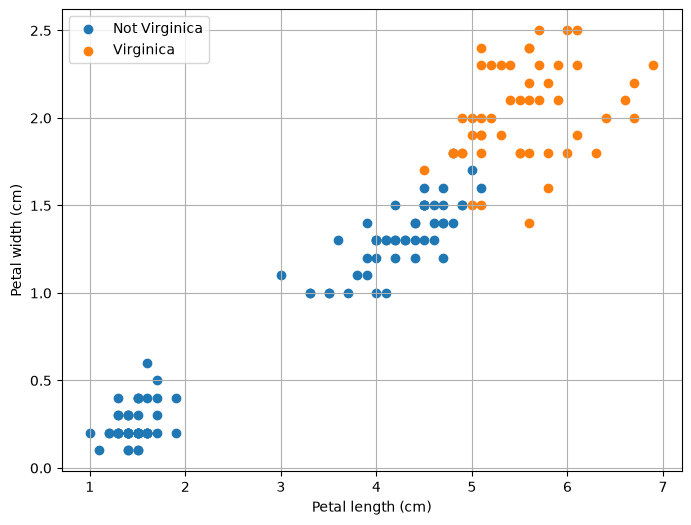

In [3]:
plt.figure(figsize=(8, 6))
plt.scatter(X[~y, 0], X[~y, 1], label="Not Virginica")
plt.scatter(X[y, 0], X[y, 1], label="Virginica")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend()
plt.grid(True)
plt.show()

# Part II — Feature scaling

SVM relies on distances and margins. If one feature has a much larger numerical range than another, it can dominate those distances. `StandardScaler` transforms each feature using its training mean and standard deviation, so the transformed feature has approximately mean 0 and standard deviation 1.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Before scaling — minimum:", X.min(axis=0))
print("Before scaling — maximum:", X.max(axis=0))
print("After scaling — mean:", X_scaled.mean(axis=0))
print("After scaling — standard deviation:", X_scaled.std(axis=0))

Before scaling — minimum: [1.  0.1]
Before scaling — maximum: [6.9 2.5]
After scaling — mean: [-1.69864123e-15 -1.40924309e-15]
After scaling — standard deviation: [1. 1.]


### Task 2.1 — Answers

1. **Why scale?** To prevent a feature's units or range from disproportionately influencing the SVM's distances and decision boundary.
2. **What happens after standardization?** Each feature has mean approximately 0 and standard deviation approximately 1. Individual values are not forced into the range 0–1.

The scaler should be fitted on training data only when evaluating generalization. A pipeline helps ensure scaling is repeated correctly inside each cross-validation fold.

# Part III — Linear SVM classification

`SVC(kernel="linear")` learns a linear decision boundary. `C` controls the penalty for training errors: a smaller C allows more violations and usually encourages a wider margin; a larger C penalizes violations more strongly.

In [5]:
linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1))
])

linear_svm.fit(X, y)
y_pred = linear_svm.predict(X)

print("First 10 predictions:", y_pred[:10])
print("Training accuracy:", accuracy_score(y, y_pred))

First 10 predictions: [False False False False False False False False False False]
Training accuracy: 0.9533333333333334


### Task 3.1 — Answers

1. **Accuracy:** With the code above, the expected training accuracy is about **0.9533 (95.33%)** in a typical scikit-learn environment.
2. **What does the model predict?** Whether each flower is Virginica (`True`) or not Virginica (`False`).
3. **Is training evaluation enough?** No. The model is evaluated on examples it has already seen, so this can overstate performance on new data.
4. **More reliable evaluation:** Use a held-out test set or cross-validation. As in Lab II, cross-validation trains and evaluates the model on multiple splits and summarizes the scores.

# Part IV — Visualize the decision boundary

The mesh grid creates many points across the two-dimensional feature space. The trained classifier predicts a class for each point; `contourf` colors the regions according to those predictions.

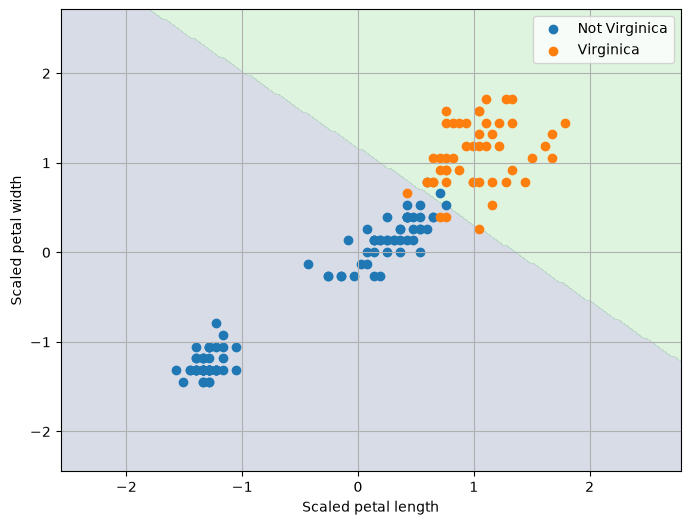

In [6]:
# Fit the model on the already standardized features, matching the PDF's approach
svm_scaled = SVC(kernel="linear", C=1)
svm_scaled.fit(X_scaled, y)

x0 = np.linspace(X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1, 200)
x1 = np.linspace(X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1, 200)
xx, yy = np.meshgrid(x0, x1)
X_grid = np.c_[xx.ravel(), yy.ravel()]
grid_predictions = svm_scaled.predict(X_grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, grid_predictions, alpha=0.2)
plt.scatter(X_scaled[~y, 0], X_scaled[~y, 1], label="Not Virginica")
plt.scatter(X_scaled[y, 0], X_scaled[y, 1], label="Virginica")
plt.xlabel("Scaled petal length")
plt.ylabel("Scaled petal width")
plt.legend()
plt.grid(True)
plt.show()

### Task 4.1 — Answers

1. **Where is the boundary?** It is the dividing line between the two differently colored prediction regions.
2. **Which observations are closest?** The observations lying nearest to that line; these are typically support vectors.
3. **What about observations near the boundary?** Their classification is less certain: small changes in measurements can move them to the other side and change the predicted class.

# Part V — Support vectors and the margin

In [20]:
print("Support-vector indices:", svm_scaled.support_)
print("Number of support vectors:", len(svm_scaled.support_))
print("Support vectors per class:", svm_scaled.n_support_)
print("Support-vector coordinates (scaled):")
print(X_scaled[svm_scaled.support_])

Support-vector indices: [ 52  54  56  68  70  72  76  77  78  83  84  85  86 101 106 119 123 126
 127 129 133 134 138 142 146 149]
Number of support vectors: 26
Support vectors per class: [13 13]
Support-vector coordinates (scaled):
[[0.64908342 0.3957741 ]
 [0.47857113 0.3957741 ]
 [0.53540856 0.52740629]
 [0.42173371 0.3957741 ]
 [0.59224599 0.79067065]
 [0.64908342 0.3957741 ]
 [0.59224599 0.26414192]
 [0.70592084 0.65903847]
 [0.42173371 0.3957741 ]
 [0.76275827 0.52740629]
 [0.42173371 0.3957741 ]
 [0.42173371 0.52740629]
 [0.53540856 0.3957741 ]
 [0.76275827 0.92230284]
 [0.42173371 0.65903847]
 [0.70592084 0.3957741 ]
 [0.64908342 0.79067065]
 [0.59224599 0.79067065]
 [0.64908342 0.79067065]
 [1.16062026 0.52740629]
 [0.76275827 0.3957741 ]
 [1.0469454  0.26414192]
 [0.59224599 0.79067065]
 [0.76275827 0.92230284]
 [0.70592084 0.92230284]
 [0.76275827 0.79067065]]


### Task 5.1 — Answers

1. **How many?** The exact count is printed by `len(svm_scaled.support_)`; it depends on the dataset and model settings. With the standard Iris data and this linear model, the count is typically 26.
2. **Location:** On or near the margin, closest to the decision boundary.
3. **Why important?** These observations largely determine the boundary. Points far away from the margin generally have little or no influence on its position.
4. **If near-boundary observations are removed:** The boundary and margin may change, and the model may classify some examples differently.

# Part VI — The C hyperparameter

In [8]:
C_values = [0.01, 0.1, 1, 10, 100]
c_results = []

for c_value in C_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=c_value))
    ])
    model.fit(X, y)
    predictions = model.predict(X)
    score = accuracy_score(y, predictions)
    n_support = model.named_steps["svm"].n_support_.sum()
    c_results.append({"C": c_value, "Training accuracy": score,
                      "Number of support vectors": int(n_support)})

pd.DataFrame(c_results)

,C,Training accuracy,Number of support vectors
0,0.01,0.960000,100
1,0.10,0.960000,54
2,1.00,0.953333,26
3,10.00,0.966667,16
4,100.00,0.960000,12


### Task 6.1 — Answers

1. **Very small C:** Training errors are penalized less. The model usually prefers a wider margin, potentially underfitting.
2. **Large C:** Training errors are penalized more. The boundary tries harder to classify training observations correctly and the margin may become narrower.
3. **Effect on margin:** Lower C generally favours a wider margin; higher C generally favours fewer training errors over margin width.
4. **Does higher training accuracy mean better generalization?** No. It can reflect overfitting. Compare cross-validation scores instead of choosing only by training accuracy.

# Part VII — Nonlinear classification with polynomial features

`PolynomialFeatures(degree=3)` adds combinations and powers of the original features. A linear SVM then learns a linear boundary in this expanded feature space, which corresponds to a nonlinear boundary in the original two-feature space.

In [9]:
poly_features_svm = Pipeline([
    ("poly_features", PolynomialFeatures(degree=3)),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=10))
])

poly_features_svm.fit(X, y)
poly_features_predictions = poly_features_svm.predict(X)
print("Polynomial-feature SVM training accuracy:",
      accuracy_score(y, poly_features_predictions))

Polynomial-feature SVM training accuracy: 0.96


### Task 7.1 — Answers

1. **Increasing polynomial degree:** Creates more complex features and allows a more flexible decision boundary.
2. **Disadvantages of very high degree:** More computation, more features, increased risk of overfitting, and harder interpretation. Higher degree does not guarantee better test performance.

# Part VIII — Polynomial kernel

In [10]:
poly_kernel_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="poly", degree=3, coef0=1, C=5))
])

poly_kernel_svm.fit(X, y)
poly_kernel_predictions = poly_kernel_svm.predict(X)
print("Polynomial-kernel training accuracy:",
      accuracy_score(y, poly_kernel_predictions))

Polynomial-kernel training accuracy: 0.96


### Task 8.1 — Answers

1. **Purpose:** The polynomial kernel lets an SVM model nonlinear relationships without explicitly building every polynomial feature.
2. **`degree`:** Controls the polynomial degree and therefore the type/complexity of interactions represented by the kernel.
3. **Degree too high:** Can make the boundary overly complex and increase overfitting and computation.
4. **Why convenient?** The kernel computes similarities as if the data were mapped into a larger feature space, without explicitly constructing that space (the kernel trick).

## RBF kernel and γ

In [11]:
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1, gamma=1))
])
rbf_svm.fit(X, y)
rbf_predictions = rbf_svm.predict(X)
print("RBF training accuracy:", accuracy_score(y, rbf_predictions))

RBF training accuracy: 0.96


### Task 8.2 — Answers

1. **Very small γ:** Each training point has a broad influence. The boundary is smoother and may underfit.
2. **Very large γ:** Each point's influence is very local. The boundary can become highly irregular.
3. **Why complex?** A large γ means similarity drops quickly with distance, allowing the model to form small, tightly fitted regions around training observations.
4. **Overfitting:** If γ is too large, the model may fit noise or individual training points rather than the underlying pattern. Use cross-validation to choose γ.

In [12]:
gamma_results = []
for gamma_value in [0.01, 0.1, 1, 10, 100]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1, gamma=gamma_value))
    ])
    model.fit(X, y)
    gamma_results.append({
        "gamma": gamma_value,
        "Training accuracy": accuracy_score(y, model.predict(X))
    })

pd.DataFrame(gamma_results)

,gamma,Training accuracy
0,0.01,0.953333
1,0.10,0.953333
2,1.00,0.960000
3,10.00,0.966667
4,100.00,0.993333


# Part IX — Compare classification models with cross-validation

This follows the lab's 5-fold cross-validation idea. Each model is trained and evaluated across five different folds. The mean is the average accuracy; the standard deviation indicates how much the score varied between folds.

In [13]:
models = {
    "Linear SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=1))
    ]),
    "Polynomial Kernel": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="poly", degree=3, coef0=1, C=5))
    ]),
    "RBF Kernel": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1, gamma=1))
    ])
}

cv_results = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")
    cv_results.append({
        "Model": name,
        "Fold scores": np.round(scores, 4).tolist(),
        "Mean accuracy": scores.mean(),
        "Std. dev.": scores.std()
    })

pd.DataFrame(cv_results)

,Model,Fold scores,Mean accuracy,Std. dev.
0,Linear SVM,"[0.9667, 0.9667, 1.0, 0.8667, 1.0]",0.960000,0.048990
1,Polynomial Kernel,"[0.9667, 0.9667, 1.0, 0.8667, 0.9667]",0.953333,0.045216
2,RBF Kernel,"[0.9667, 0.9667, 1.0, 0.8667, 0.9667]",0.953333,0.045216


### Task 9.1 — Answers and interpretation

The table generated above is the result to report from your own environment. On a typical run with scikit-learn and the default non-shuffled 5-fold split, results are approximately:

| Model | Mean accuracy | Standard deviation |
|---|---:|---:|
| Linear SVM | 0.960 | 0.049 |
| Polynomial Kernel | 0.953 | 0.045 |
| RBF Kernel | 0.953 | 0.045 |

Small differences may occur with different library versions or cross-validation settings.

1. **How do they compare?** These configurations perform similarly; the linear SVM is slightly higher in this particular comparison. This does not mean it will always be best.
2. **Most influential hyperparameters:** `C`, the kernel choice, polynomial `degree`, and RBF `gamma`.
3. **Why cross-validation?** Training accuracy measures performance on the data used to fit the model. Cross-validation gives a better estimate of performance on unseen data and makes model comparisons more meaningful.

# Part X — SVM for regression

Regression predicts a number rather than a class. This part uses the California Housing dataset. The target is the median house value in the dataset's units. We split the data before fitting the scaler/model so the test set remains unseen during training.

In [14]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
X_house = housing.data
y_house = housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X_house, y_house, test_size=0.2, random_state=42
)

linear_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", LinearSVR(epsilon=0.5, random_state=42, max_iter=10000))
])

linear_svr.fit(X_train, y_train)
y_pred_linear = linear_svr.predict(X_test)

rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
print("Linear SVR RMSE:", rmse_linear)

Linear SVR RMSE: 0.7504432215921479


### Task 10.1 — Answers

1. **Classification vs regression:** SVM classification predicts a class label (for example, Virginica or not). SVM regression predicts a numeric value (for example, house value).
2. **`epsilon` (ϵ):** Defines the width of the insensitive tube around the regression prediction. Errors inside this tube are not penalized by the epsilon-insensitive loss. A larger epsilon can ignore more small deviations, but may reduce prediction precision.

# Part XI — Nonlinear SVM regression with an RBF kernel

The RBF SVR can model nonlinear relationships. `C` controls the penalty for errors outside the epsilon tube, `gamma` controls how local the RBF influence is, and `epsilon` controls the tube width. RMSE is the square root of mean squared error; lower RMSE is better on the same test set.

In [15]:
rbf_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf", C=100, gamma="scale", epsilon=0.1))
])

rbf_svr.fit(X_train, y_train)
y_pred_rbf = rbf_svr.predict(X_test)
rmse_rbf = np.sqrt(mean_squared_error(y_test, y_pred_rbf))
print("RBF SVR RMSE:", rmse_rbf)

RBF SVR RMSE: 0.5657769203688406


### Task 11.1 — Compare SVR hyperparameters

The following experiment holds the train/test split fixed and changes one or more hyperparameters. It can take some time because the housing dataset is relatively large. Treat the RMSE values printed by your notebook as the results to submit.

In [16]:
svr_settings = [
    {"C": 10,  "gamma": "scale", "epsilon": 0.1},
    {"C": 100, "gamma": "scale", "epsilon": 0.1},
    {"C": 300, "gamma": "scale", "epsilon": 0.1},
    {"C": 100, "gamma": 0.01,    "epsilon": 0.1},
    {"C": 100, "gamma": 0.1,     "epsilon": 0.1},
    {"C": 100, "gamma": "scale", "epsilon": 0.5},
]

svr_results = []
for setting in svr_settings:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(
            kernel="rbf",
            C=setting["C"],
            gamma=setting["gamma"],
            epsilon=setting["epsilon"]
        ))
    ])
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    svr_results.append({
        "C": setting["C"],
        "gamma": setting["gamma"],
        "epsilon": setting["epsilon"],
        "RMSE": rmse
    })

pd.DataFrame(svr_results).sort_values("RMSE")

,C,gamma,epsilon,RMSE
5,100,scale,0.5,0.559810
1,100,scale,0.1,0.565777
0,10,scale,0.1,0.568944
4,100,0.1,0.1,0.569651
2,300,scale,0.1,0.580542
3,100,0.01,0.1,0.733430


### Task 11.1 — Answers

1. **Which parameters had the greatest effect?** It depends on the dataset and tested values. Compare the RMSE table; `C` and `gamma` often have a substantial effect, while `epsilon` changes which residuals are penalized.
2. **Does increasing C always improve the model?** No. A higher C may fit the training data more closely but can generalize worse and can increase computation.
3. **What happens when gamma increases?** The RBF influence becomes more local and the fitted function can become more complex. If too large, it can overfit; if too small, it can underfit.

# Part XII — Classification or regression?

| Aspect | Classification | Regression |
|---|---|---|
| Goal | Predict a class | Predict a number |
| Lab example | Virginica vs not Virginica | California house value |
| Scikit-learn model | `SVC` | `SVR` or `LinearSVR` |
| Typical evaluation | Accuracy, precision/recall | RMSE, MAE, R² |

## Final reminders

- Run the notebook cells in order.
- Use the values generated in your own environment for any numerical results you submit.
- Do not claim that training accuracy is test accuracy.
- Keep scaling inside a `Pipeline` when using cross-validation to avoid data leakage.
- If California Housing cannot be downloaded, include the exact error message when asking for help; Iris parts do not require that download.